# ClusterBP v2: временная валидация

Модели обучаются на прошлом и проверяются на будущем, как при внедрении:

- **обучение:** окна с отсечкой до 1 октября 2024 года, исход которых полностью известен к этой дате (отсечка + 14 дней ≤ 01.10.2024);
- **внутренняя валидация:** последние 30 дней обучающего периода — на ней ранняя остановка, пороги и веса смеси;
- **тест:** все окна с отсечкой с 1 октября 2024 года (октябрь 2024 – январь 2025);
- отдельно — **новые пациенты**: тестовые окна пациентов, у которых нет ни одного окна в обучающем периоде.

Фенотипы GDTW строятся по первым 30 дням пациентов, которые целиком пришлись на обучающий период.
Модели и признаки те же, что в `clusterbp_v2.ipynb`.

In [1]:
import os
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score

from clusterbp_lib import (DATA_DIR, MODELS_DIR, RESULTS_DIR, SEED, TARGETS, FEATURE_SETS, LR_COLS, N_CLUSTERS,
                           fit_phenotypes, assign_phenotypes, set_phenotype_columns, fit_xgb, train_gru,
                           gru_logits, sigmoid, logit, best_threshold, tune_blend, apply_blend, boot_eval, ci)

warnings.filterwarnings('ignore')
torch.set_num_threads(os.cpu_count())

SPLIT = pd.Timestamp('2024-10-01')
LAG = max(cfg['gap'] + cfg['horizon'] for cfg in TARGETS.values())   # 14 дней: исход окна известен через LAG
VAL_DAYS = 30
TEMPORAL_TARGETS = [n for n, cfg in TARGETS.items() if cfg['full']]
N_BOOT = 1000

win = pd.read_parquet(os.path.join(DATA_DIR, 'windows.parquet'))
X_seq = np.load(os.path.join(DATA_DIR, 'X_seq.npy'))
seq_len = np.load(os.path.join(DATA_DIR, 'seq_len.npy'))
pheno_win = np.load(os.path.join(DATA_DIR, 'pheno_win.npy'))
pheno_first = np.load(os.path.join(DATA_DIR, 'pheno_first.npy'))
pheno_first_pid = np.load(os.path.join(DATA_DIR, 'pheno_first_pid.npy'))
first_day = pd.read_parquet(os.path.join(DATA_DIR, 'measurements.parquet'), columns=['pid', 'td']) \
              .groupby('pid')['td'].min().apply(np.floor)

T = SPLIT.value / 86400e9          # дни от 1970-01-01, как win['cut']
cut, pid = win['cut'].values, win['pid'].values
train_all = cut + LAG <= T
va = train_all & (cut > T - LAG - VAL_DAYS)
tr = train_all & ~va
te = cut >= T
new_pat = te & ~np.isin(pid, np.unique(pid[train_all]))
month = pd.to_datetime(cut * 86400, unit='s').to_period('M').astype(str)

summary = pd.DataFrame({
    'окон': [tr.sum(), va.sum(), te.sum(), new_pat.sum()],
    'пациентов': [len(np.unique(pid[m])) for m in [tr, va, te, new_pat]],
    'период': [f'{month[m].min()} – {month[m].max()}' for m in [tr, va, te, new_pat]],
}, index=['обучение', 'валидация', 'тест', 'тест: новые пациенты'])
for t in TEMPORAL_TARGETS:
    summary[f'доля событий {t}'] = [win[f'y_{t}'].values[m].mean() for m in [tr, va, te, new_pat]]
summary

,окон,пациентов,период,доля событий A,доля событий B,доля событий OLD
обучение,278518,8195,2023-11 – 2024-08,0.047595,0.124064,0.040446
валидация,43546,5186,2024-08 – 2024-09,0.045791,0.122996,0.039154
тест,81130,4564,2024-10 – 2025-01,0.043375,0.159374,0.040478
тест: новые пациенты,8797,675,2024-10 – 2025-01,0.038309,0.143458,0.034785


## Фенотипы и обучение

In [2]:
eligible = first_day.index.values[(first_day.values + 30 <= T - LAG)]
templates, sizes, vol = fit_phenotypes(pheno_first, pheno_first_pid, eligible, SEED)
cl, dist = assign_phenotypes(pheno_win, templates)
set_phenotype_columns(win, cl, dist)
np.save(os.path.join(MODELS_DIR, 'templates_temporal.npy'), templates)
print('Пациентов для шаблонов (до отбора по полноте 30 дней):', len(eligible), '; размеры кластеров:', sizes)

preds, params_log = {}, []
t_all = time.time()
for t in TEMPORAL_TARGETS:
    t0 = time.time()
    y = win[f'y_{t}'].values
    res = {'rule_persist': (win[f'ev_{t}_7'].values.astype(float), None),
           'rule_maxSBP': (win['sbp_max'].values, None)}

    lr = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000))
    lr.fit(win.loc[tr, LR_COLS].values, y[tr])
    res['LR'] = (lr.predict_proba(win[LR_COLS].values)[:, 1], None)

    for fs in ['paper6', 'full']:
        cols = FEATURE_SETS[fs]
        m = fit_xgb(win.loc[tr, cols].values, y[tr], win.loc[va, cols].values, y[va], SEED)
        m.save_model(os.path.join(MODELS_DIR, f'xgb_{fs}_{t}_temporal.json'))
        res[f'XGB_{fs}'] = (m.predict_proba(win[cols].values)[:, 1], None)

    model, mu, sd, corr, log = train_gru(X_seq[tr], seq_len[tr], y[tr], X_seq[va], seq_len[va], y[va], SEED)
    torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd, 'corr': corr},
               os.path.join(MODELS_DIR, f'gru_{t}_temporal.pt'))
    pg = sigmoid(gru_logits(model, X_seq, seq_len, mu, sd) + corr)
    res['GRU'] = (pg, None)

    for suffix, xname in [('', 'XGB_paper6'), ('_full', 'XGB_full')]:
        px = res[xname][0]
        res[f'Blend_global{suffix}'] = apply_blend(pg, px, tune_blend(y[va], pg[va], px[va]))
        cp = tune_blend(y[va], pg[va], px[va], clusters=cl[va])
        res[f'ClusterBP{suffix}'] = apply_blend(pg, px, cp, clusters=cl)
        for key, (w, thr) in cp.items():
            params_log.append({'target': t, 'variant': 'ClusterBP' + suffix, 'cluster': key, 'w_gru': w, 'threshold': thr})
    stack = LogisticRegression(max_iter=3000).fit(np.column_stack([logit(pg[va]), logit(res['XGB_full'][0][va])]), y[va])
    res['Stack_full'] = (stack.predict_proba(np.column_stack([logit(pg), logit(res['XGB_full'][0])]))[:, 1], None)

    for name, (score, pred) in list(res.items()):
        if pred is None:
            thr, _ = best_threshold(y[va], score[va])
            res[name] = (score, (score > thr).astype(np.int8))
    preds[t] = res
    print(f'{t}: {time.time() - t0:.0f} с, эпох GRU: {len(log)}')
print(f'Всего: {(time.time() - t_all) / 60:.1f} мин')
pd.DataFrame(params_log).to_csv(os.path.join(RESULTS_DIR, 'temporal_clusterbp_params.csv'), index=False)

Пациентов для шаблонов (до отбора по полноте 30 дней): 9642 ; размеры кластеров: [360 720 420]


A: 54 с, эпох GRU: 20


B: 124 с, эпох GRU: 22


OLD: 45 с, эпох GRU: 18
Всего: 3.7 мин


## Качество на будущих окнах

Для сравнения добавлен столбец `AUPRC в CV` из `clusterbp_v2.ipynb` (случайное разбиение по пациентам).
95% ДИ — бутстреп по пациентам тестового периода.

In [3]:
MODEL_ORDER = ['Stack_full', 'ClusterBP_full', 'Blend_global_full', 'XGB_full', 'LR', 'GRU', 'ClusterBP',
               'Blend_global', 'XGB_paper6', 'rule_maxSBP', 'rule_persist']
tables = {}
for t in TEMPORAL_TARGETS:
    cv = pd.read_csv(os.path.join(RESULTS_DIR, f'metrics_{t}.csv'), index_col=0)
    blocks = []
    for label, mask in [('все пациенты', te), ('новые пациенты', new_pat)]:
        y = win[f'y_{t}'].values[mask].astype(float)
        models = [(preds[t][m][0][mask], preds[t][m][1][mask].astype(float)) for m in MODEL_ORDER]
        B = boot_eval(y, pid[mask], models, n_boot=N_BOOT)
        rows = []
        for j, m in enumerate(MODEL_ORDER):
            s, p = models[j]
            tp = ((p == 1) & (y == 1)).sum(); fp = ((p == 1) & (y == 0)).sum(); fn = ((p == 0) & (y == 1)).sum()
            rows.append({'тест': label, 'model': m,
                         'AUROC': roc_auc_score(y, s), 'AUROC 95% ДИ': ci(B[:, j, 0]),
                         'AUPRC': average_precision_score(y, s), 'AUPRC 95% ДИ': ci(B[:, j, 1]),
                         'macro_F1': f1_score(y, p, average='macro'), 'macro_F1 95% ДИ': ci(B[:, j, 2]),
                         'sensitivity': tp / (tp + fn), 'PPV': tp / max(tp + fp, 1),
                         'AUPRC в CV': cv.loc[m, 'AUPRC'] if m in cv.index else np.nan})
        blocks.append(pd.DataFrame(rows))
    tables[t] = pd.concat(blocks).set_index(['тест', 'model'])
    tables[t].to_csv(os.path.join(RESULTS_DIR, f'temporal_metrics_{t}.csv'))
    print(f"\n=== {TARGETS[t]['title']}: тест {SPLIT:%d.%m.%Y} и позже ===")
    display(tables[t].round(3))


=== A: острый подъём (красные зоны): тест 01.10.2024 и позже ===


AUROC    AUROC 95% ДИ  AUPRC  \
тест           model                                             
все пациенты   Stack_full         0.892  [0.881; 0.903]  0.434   
               ClusterBP_full     0.890  [0.879; 0.901]  0.432   
               Blend_global_full  0.889  [0.877; 0.900]  0.427   
               XGB_full           0.892  [0.881; 0.903]  0.431   
               LR                 0.865  [0.851; 0.877]  0.393   
               GRU                0.866  [0.852; 0.878]  0.389   
               ClusterBP          0.871  [0.857; 0.883]  0.390   
               Blend_global       0.871  [0.858; 0.883]  0.390   
               XGB_paper6         0.828  [0.809; 0.846]  0.306   
               rule_maxSBP        0.815  [0.795; 0.835]  0.252   
               rule_persist       0.682  [0.662; 0.700]  0.248   
новые пациенты Stack_full         0.858  [0.818; 0.890]  0.343   
               ClusterBP_full     0.857  [0.815; 0.889]  0.344   
               Blend_global_full  0.860  [0.818; 0.892]  0.338   
               XGB_full           0.855  [0.815; 0.887]  0.341   
               LR                 0.836  [0.792; 0.871]  0.318   
               GRU                0.845  [0.803; 0.878]  0.304   
               ClusterBP          0.845  [0.801; 0.880]  0.297   
               Blend_global       0.845  [0.802; 0.881]  0.297   
               XGB_paper6         0.757  [0.667; 0.837]  0.217   
               rule_maxSBP        0.740  [0.654; 0.819]  0.164   
               rule_persist       0.648  [0.598; 0.696]  0.189   

                                    AUPRC 95% ДИ  macro_F1 macro_F1 95% ДИ  \
тест           model                                                         
все пациенты   Stack_full         [0.383; 0.481]     0.703  [0.685; 0.719]   
               ClusterBP_full     [0.383; 0.479]     0.700  [0.681; 0.717]   
               Blend_global_full  [0.377; 0.476]     0.702  [0.683; 0.719]   
               XGB_full           [0.381; 0.478]     0.701  [0.683; 0.718]   
               LR                 [0.342; 0.442]     0.688  [0.669; 0.707]   
               GRU                [0.340; 0.438]     0.688  [0.669; 0.706]   
               ClusterBP          [0.340; 0.437]     0.688  [0.669; 0.707]   
               Blend_global       [0.340; 0.438]     0.688  [0.670; 0.706]   
               XGB_paper6         [0.259; 0.355]     0.660  [0.643; 0.675]   
               rule_maxSBP        [0.215; 0.292]     0.648  [0.633; 0.664]   
               rule_persist       [0.204; 0.292]     0.676  [0.658; 0.693]   
новые пациенты Stack_full         [0.226; 0.465]     0.672  [0.623; 0.719]   
               ClusterBP_full     [0.229; 0.461]     0.667  [0.614; 0.718]   
               Blend_global_full  [0.224; 0.452]     0.675  [0.624; 0.724]   
               XGB_full           [0.222; 0.461]     0.670  [0.622; 0.716]   
               LR                 [0.195; 0.451]     0.670  [0.615; 0.725]   
               GRU                [0.203; 0.413]     0.661  [0.610; 0.709]   
               ClusterBP          [0.203; 0.394]     0.667  [0.616; 0.717]   
               Blend_global       [0.203; 0.397]     0.664  [0.614; 0.714]   
               XGB_paper6         [0.144; 0.310]     0.616  [0.579; 0.651]   
               rule_maxSBP        [0.108; 0.239]     0.599  [0.563; 0.638]   
               rule_persist       [0.099; 0.305]     0.638  [0.592; 0.683]   

                                  sensitivity    PPV  AUPRC в CV  
тест           model                                              
все пациенты   Stack_full               0.457  0.410         NaN  
               ClusterBP_full           0.430  0.422       0.449  
               Blend_global_full        0.402  0.457       0.449  
               XGB_full                 0.458  0.405       0.448  
               LR                       0.383  0.423       0.418  
               GRU                      0.386  0.418       0.403  
               ClusterBP                


=== B: превышение целевого АД (через неделю): тест 01.10.2024 и позже ===


AUROC    AUROC 95% ДИ  AUPRC  \
тест           model                                             
все пациенты   Stack_full         0.818  [0.807; 0.828]  0.582   
               ClusterBP_full     0.817  [0.806; 0.827]  0.582   
               Blend_global_full  0.817  [0.806; 0.827]  0.582   
               XGB_full           0.816  [0.806; 0.827]  0.580   
               LR                 0.815  [0.805; 0.825]  0.552   
               GRU                0.810  [0.799; 0.820]  0.558   
               ClusterBP          0.812  [0.801; 0.822]  0.558   
               Blend_global       0.813  [0.802; 0.824]  0.557   
               XGB_paper6         0.782  [0.771; 0.793]  0.473   
               rule_maxSBP        0.718  [0.706; 0.730]  0.336   
               rule_persist       0.690  [0.677; 0.702]  0.403   
новые пациенты Stack_full         0.815  [0.785; 0.843]  0.527   
               ClusterBP_full     0.815  [0.784; 0.842]  0.527   
               Blend_global_full  0.815  [0.784; 0.842]  0.527   
               XGB_full           0.813  [0.783; 0.841]  0.523   
               LR                 0.819  [0.790; 0.845]  0.486   
               GRU                0.810  [0.780; 0.837]  0.502   
               ClusterBP          0.811  [0.782; 0.837]  0.490   
               Blend_global       0.811  [0.780; 0.837]  0.478   
               XGB_paper6         0.766  [0.735; 0.796]  0.349   
               rule_maxSBP        0.708  [0.677; 0.739]  0.268   
               rule_persist       0.675  [0.640; 0.708]  0.362   

                                    AUPRC 95% ДИ  macro_F1 macro_F1 95% ДИ  \
тест           model                                                         
все пациенты   Stack_full         [0.557; 0.609]     0.736  [0.724; 0.747]   
               ClusterBP_full     [0.557; 0.608]     0.733  [0.722; 0.745]   
               Blend_global_full  [0.557; 0.609]     0.736  [0.725; 0.748]   
               XGB_full           [0.555; 0.607]     0.732  [0.720; 0.744]   
               LR                 [0.525; 0.579]     0.726  [0.714; 0.738]   
               GRU                [0.532; 0.584]     0.725  [0.714; 0.736]   
               ClusterBP          [0.533; 0.584]     0.728  [0.717; 0.739]   
               Blend_global       [0.532; 0.583]     0.726  [0.715; 0.737]   
               XGB_paper6         [0.446; 0.502]     0.680  [0.669; 0.693]   
               rule_maxSBP        [0.314; 0.360]     0.633  [0.622; 0.644]   
               rule_persist       [0.377; 0.429]     0.686  [0.674; 0.698]   
новые пациенты Stack_full         [0.442; 0.608]     0.714  [0.679; 0.746]   
               ClusterBP_full     [0.441; 0.606]     0.713  [0.679; 0.746]   
               Blend_global_full  [0.442; 0.607]     0.716  [0.681; 0.748]   
               XGB_full           [0.438; 0.605]     0.703  [0.665; 0.738]   
               LR                 [0.405; 0.567]     0.696  [0.660; 0.730]   
               GRU                [0.418; 0.583]     0.717  [0.685; 0.746]   
               ClusterBP          [0.407; 0.572]     0.710  [0.680; 0.740]   
               Blend_global       [0.399; 0.560]     0.708  [0.677; 0.738]   
               XGB_paper6         [0.292; 0.411]     0.643  [0.614; 0.674]   
               rule_maxSBP        [0.224; 0.320]     0.606  [0.579; 0.632]   
               rule_persist       [0.287; 0.436]     0.666  [0.634; 0.698]   

                                  sensitivity    PPV  AUPRC в CV  
тест           model                                              
все пациенты   Stack_full               0.485  0.626         NaN  
               ClusterBP_full           0.470  0.636       0.677  
               Blend_global_full        0.489  0.623       0.677  
               XGB_full                 0.456  0.651       0.676  
               LR                       0.478  0.595       0.631  
               GRU                      0.485  0.586       0.643  
               ClusterBP                


=== OLD: цель из первой версии статьи: тест 01.10.2024 и позже ===


AUROC    AUROC 95% ДИ  AUPRC  \
тест           model                                             
все пациенты   Stack_full         0.920  [0.911; 0.927]  0.470   
               ClusterBP_full     0.919  [0.910; 0.927]  0.470   
               Blend_global_full  0.920  [0.911; 0.927]  0.470   
               XGB_full           0.918  [0.909; 0.925]  0.466   
               LR                 0.903  [0.893; 0.912]  0.424   
               GRU                0.906  [0.896; 0.915]  0.428   
               ClusterBP          0.910  [0.900; 0.918]  0.426   
               Blend_global       0.910  [0.901; 0.919]  0.433   
               XGB_paper6         0.895  [0.886; 0.905]  0.362   
               rule_maxSBP        0.888  [0.878; 0.898]  0.293   
               rule_persist       0.690  [0.673; 0.707]  0.263   
новые пациенты Stack_full         0.898  [0.872; 0.922]  0.378   
               ClusterBP_full     0.897  [0.870; 0.921]  0.375   
               Blend_global_full  0.899  [0.873; 0.923]  0.377   
               XGB_full           0.895  [0.867; 0.919]  0.373   
               LR                 0.895  [0.869; 0.920]  0.348   
               GRU                0.889  [0.864; 0.914]  0.337   
               ClusterBP          0.892  [0.866; 0.916]  0.335   
               Blend_global       0.892  [0.866; 0.917]  0.343   
               XGB_paper6         0.870  [0.838; 0.898]  0.288   
               rule_maxSBP        0.869  [0.839; 0.896]  0.206   
               rule_persist       0.668  [0.631; 0.706]  0.201   

                                    AUPRC 95% ДИ  macro_F1 macro_F1 95% ДИ  \
тест           model                                                         
все пациенты   Stack_full         [0.423; 0.515]     0.719  [0.702; 0.736]   
               ClusterBP_full     [0.422; 0.514]     0.717  [0.699; 0.733]   
               Blend_global_full  [0.422; 0.514]     0.720  [0.702; 0.736]   
               XGB_full           [0.418; 0.511]     0.718  [0.701; 0.735]   
               LR                 [0.374; 0.471]     0.705  [0.687; 0.721]   
               GRU                [0.380; 0.473]     0.703  [0.685; 0.719]   
               ClusterBP          [0.377; 0.472]     0.699  [0.680; 0.716]   
               Blend_global       [0.383; 0.478]     0.703  [0.685; 0.719]   
               XGB_paper6         [0.313; 0.410]     0.678  [0.659; 0.697]   
               rule_maxSBP        [0.254; 0.336]     0.667  [0.650; 0.684]   
               rule_persist       [0.218; 0.306]     0.694  [0.675; 0.711]   
новые пациенты Stack_full         [0.285; 0.462]     0.694  [0.652; 0.736]   
               ClusterBP_full     [0.282; 0.459]     0.681  [0.638; 0.725]   
               Blend_global_full  [0.288; 0.461]     0.691  [0.647; 0.733]   
               XGB_full           [0.281; 0.457]     0.691  [0.649; 0.731]   
               LR                 [0.255; 0.441]     0.680  [0.636; 0.722]   
               GRU                [0.251; 0.425]     0.667  [0.627; 0.707]   
               ClusterBP          [0.242; 0.429]     0.663  [0.621; 0.705]   
               Blend_global       [0.251; 0.435]     0.666  [0.624; 0.705]   
               XGB_paper6         [0.199; 0.380]     0.626  [0.585; 0.663]   
               rule_maxSBP        [0.148; 0.277]     0.616  [0.578; 0.651]   
               rule_persist       [0.131; 0.279]     0.663  [0.625; 0.700]   

                                  sensitivity    PPV  AUPRC в CV  
тест           model                                              
все пациенты   Stack_full               0.443  0.479         NaN  
               ClusterBP_full           0.449  0.466       0.526  
               Blend_global_full        0.445  0.479       0.525  
               XGB_full                 0.458  0.460       0.524  
               LR                       0.449  0.421       0.475  
               GRU                      0.390  0.472       0.470  
               ClusterBP                

## Качество по месяцам тестового периода

Если качество падает от месяца к месяцу или меняется доля событий, это сдвиг распределения во времени.

,target,месяц,окон,доля событий,AUPRC Stack_full,AUPRC XGB_full,AUPRC ClusterBP,AUPRC rule_maxSBP
0,A,2024-10,36607,0.042,0.405,0.403,0.361,0.221
1,A,2024-11,30060,0.043,0.457,0.454,0.410,0.277
2,A,2024-12,14459,0.048,0.460,0.458,0.425,0.291
3,B,2024-10,36607,0.172,0.556,0.554,0.535,0.326
4,B,2024-11,30060,0.115,0.686,0.683,0.653,0.340
5,B,2024-12,14459,0.220,0.569,0.569,0.537,0.388
6,OLD,2024-10,36607,0.037,0.439,0.435,0.396,0.254
7,OLD,2024-11,30060,0.041,0.490,0.485,0.440,0.324
8,OLD,2024-12,14459,0.049,0.512,0.505,0.480,0.342


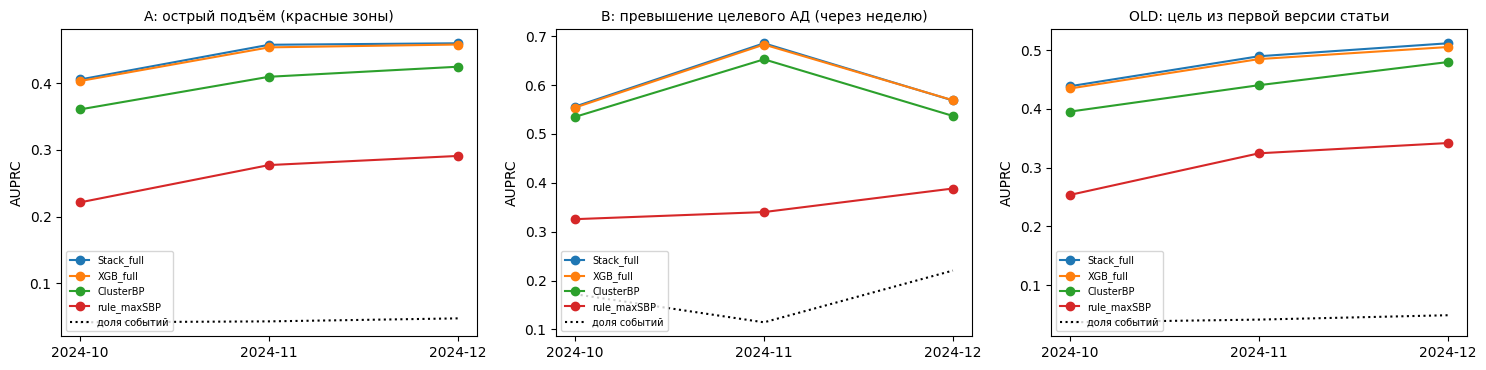

In [4]:
rows = []
for t in TEMPORAL_TARGETS:
    y = win[f'y_{t}'].values
    for mo in sorted(np.unique(month[te])):
        mask = te & (month == mo)
        if y[mask].sum() < 20:
            continue
        row = {'target': t, 'месяц': mo, 'окон': int(mask.sum()), 'доля событий': y[mask].mean()}
        for m in ['Stack_full', 'XGB_full', 'ClusterBP', 'rule_maxSBP']:
            row[f'AUPRC {m}'] = average_precision_score(y[mask], preds[t][m][0][mask])
        rows.append(row)
monthly = pd.DataFrame(rows)
monthly.to_csv(os.path.join(RESULTS_DIR, 'temporal_monthly.csv'), index=False)
display(monthly.round(3))

fig, axes = plt.subplots(1, len(TEMPORAL_TARGETS), figsize=(5 * len(TEMPORAL_TARGETS), 3.8))
for ax, t in zip(np.atleast_1d(axes), TEMPORAL_TARGETS):
    sub = monthly[monthly.target == t]
    for m in ['Stack_full', 'XGB_full', 'ClusterBP', 'rule_maxSBP']:
        ax.plot(sub['месяц'], sub[f'AUPRC {m}'], 'o-', label=m)
    ax.plot(sub['месяц'], sub['доля событий'], 'k:', label='доля событий')
    ax.set_title(TARGETS[t]['title'], fontsize=10)
    ax.set_ylabel('AUPRC')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'temporal_monthly.png'), dpi=200, bbox_inches='tight')
plt.show()